# Notebook 2 (Colab) — Anti-spoofing classifier: live vs spoof

```
YOLO face (notebook 1) → crop หน้า (×1.5) → anti-spoof classifier (notebook นี้) → face embedding → matching
```

**เป้าหมาย:** โมเดลที่ใช้ได้กับ **กล้องที่ไม่รู้จักล่วงหน้า** ไม่ใช่ accuracy สูงสุดบน CelebA-Spoof

### ปัญหาพื้นที่ดิสก์ และวิธีแก้
CelebA-Spoof zip ใหญ่ **77 GB** แต่ดิสก์ Colab ว่าง ~75 GB → `kaggle datasets download` + `unzip` ใช้ไม่ได้
notebook นี้จึง **โหลดแบบ stream**: อ่าน zip จาก Kaggle ทีละส่วนแล้วแตกไฟล์ทันที เก็บเฉพาะ
- `metas/` (ไฟล์ label)
- ภาพของ **คนที่ subject ID หารด้วย 5 ลงตัว** (~20% ของคน, เก็บทุกภาพของคนนั้น) ≈ 110k ภาพ ~15 GB

โหลดครั้งเดียว (~15–40 นาที) แล้ว crop เก็บไว้ใน Drive → รันครั้งต่อไปข้ามการโหลดทั้งหมด

### ก่อนรัน
1. Colab Secrets (รูปกุญแจ): `KAGGLE_USER`, `KAGGLE_KEY` (เปิด notebook access)
2. Runtime: GPU (L4 แนะนำ / T4 ก็ได้)
3. `Runtime → Run all` — ถ้าหลุดกลางทาง Run all ใหม่ได้ (crop cache + checkpoint อยู่ใน Drive)

### หลักการสำคัญ
- crop ด้วย **YOLO ตัวเดียวกันและวิธีเดียวกับระบบจริง**
- แบ่ง train/val **ตามคน (subject)** — ไม่ให้คนเดียวกันอยู่ทั้งสองฝั่ง
- threshold เลือกที่จุด EER บน val แล้วใช้ค่าเดิมกับรูปที่เราถ่ายเอง (ถ้ามี)
- เลือกโมเดลจาก val เท่านั้น (clean + "กล้องเสื่อม")

## 1. ติดตั้ง library, mount Drive, เช็ก GPU

In [ ]:
!pip install -q -U timm albumentations ultralytics onnx onnxruntime stream-unzip

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 141.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 107.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.3/271.3 kB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 111.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 707.4/707.4 kB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 12.2 MB/s eta 0:00:00


In [ ]:
import os, json, time, math, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()
NUM_WORKERS = os.cpu_count() or 2

print(f"torch {torch.__version__} | timm {timm.__version__} | albumentations {A.__version__}")
print(f"GPUs: {N_GPUS} -> {[torch.cuda.get_device_name(i) for i in range(N_GPUS)]} | CPU cores: {NUM_WORKERS}")

from google.colab import drive
drive.mount("/content/drive")

torch 2.11.0+cu130 | timm 1.0.30 | albumentations 2.0.8
GPUs: 1 -> ['NVIDIA L4'] | CPU cores: 12
Mounted at /content/drive


## 2. Config (แก้ค่าที่นี่ที่เดียว)

**ค่าที่เลือกไว้และเหตุผล**
- `KEEP_SUBJECT_EVERY = 5` — เก็บ 1 ใน 5 ของคน (ทุกภาพของคนนั้น) พอสำหรับสุ่ม 40k ภาพแบบ balance และยังแบ่งตามคนได้
- `YOLO_IMGSZ = 640` — หน้าใหญ่แบบ kiosk; notebook 1 พบว่าหน้าใหญ่ที่ 640 แม่นเท่า 960 แต่เร็วกว่า
- `CROP_SCALE = 1.5` — ให้เห็นขอบหน้า/ขอบจอ/ขอบกระดาษ ซึ่งเป็นหลักฐานการโกง; กรอบล้นขอบภาพ → เลื่อนกลับเข้ามาในภาพ (ไม่ยืดภาพ)
- `BATCH = 128` (L4) — ถ้าใช้ T4 แล้ว out of memory ให้ลดเป็น 64
- `EMA_DECAY = 0.998` — ~265 step/epoch × 12 epoch; EMA เฉลี่ยประมาณ 500 step ล่าสุด (~2 epoch)

In [ ]:
# ---- Paths ----
DRIVE_DIR = Path("/content/drive/MyDrive/roll_call/antispoof")
YOLO_WEIGHTS = Path("/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/export/yolo26s_widerface_960_best.pt")
MY_TEST_DIR = DRIVE_DIR / "my_test"      # optional: our own photos, folders live/ and spoof/<attack>/

CELEBA_DIR = Path("/content/celeba-spoofing")          # streamed (partial) dataset on local disk
CELEBA_ROOT = CELEBA_DIR / "CelebA_Spoof"
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/mabdullahsajid/celeba-spoofing"
KEEP_SUBJECT_EVERY = 5                                 # keep people whose subject ID % 5 == 0

CROP_DIR = Path("/content/crops")                      # crops on local disk (fast)
CACHE_DIR = DRIVE_DIR / "cache"                        # crop zip + csv on Drive (survives disconnects)
RUNS_DIR = DRIVE_DIR / "runs"
EXPORT_DIR = DRIVE_DIR / "export"
WORK_DIR = DRIVE_DIR

# ---- Face crop (must match the production pipeline) ----
YOLO_IMGSZ = 640
YOLO_CONF = 0.25
CROP_SCALE = 1.5
CROP_SAVE_SIZE = 256
IMG_SIZE = 224

# ---- Data ----
N_SAMPLES = 40000          # train + val, 50% live / 50% spoof
VAL_FRAC = 0.15

# ---- Experiments ----
BACKBONES = ["mobilenetv3_large_100", "efficientnet_b0", "convnext_nano"]
RUN_NOAUG_ABLATION = True
RUN_MIXUP_ABLATION = False

# ---- Training ----
EPOCHS = 10
BATCH = 128
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 1
LABEL_SMOOTHING = 0.1
EMA_DECAY = 0.998

# ---- Augmentation / evaluation ----
AUG_P = 0.7
AUG_MAX_OPS = 3
DEGRADED_ROUNDS = 3
USE_TTA_FLIP = True
SEED = 42

for d in (CROP_DIR, CACHE_DIR, RUNS_DIR, EXPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert YOLO_WEIGHTS.exists(), f"YOLO weights not found: {YOLO_WEIGHTS}"

CELEBA_CROPS = CROP_DIR / "celeba"
CROP_TAG = f"celeba_n{N_SAMPLES}_s{CROP_SCALE}_keep{KEEP_SUBJECT_EVERY}"
CACHE_ZIP = CACHE_DIR / f"{CROP_TAG}.zip"
CELEBA_CSV = CACHE_DIR / f"{CROP_TAG}.csv"
CACHE_READY = CELEBA_CSV.exists() and CACHE_ZIP.exists()
print("crop cache on Drive:", "FOUND -> skip download/crop" if CACHE_READY else "not found -> download + crop")

crop cache on Drive: FOUND -> skip download/crop


## 3. โหลด CelebA-Spoof แบบ stream (เก็บเฉพาะไฟล์ที่ใช้)
1. ใส่ Kaggle key จาก Colab Secrets
2. ขอไฟล์ zip จาก Kaggle แล้ว **แตกไฟล์ระหว่างโหลด** (`stream-unzip`) — ไม่มีไฟล์ zip 77 GB บนดิสก์
3. เก็บ `metas/` ทั้งหมด + ภาพและ `*_BB.txt` ของคนที่ `subject ID % KEEP_SUBJECT_EVERY == 0`
4. ไฟล์อื่นอ่านผ่านแล้วทิ้ง (ต้องอ่านให้จบเพื่อไปไฟล์ถัดไปใน zip)

ถ้ามี crop cache ใน Drive แล้ว cell นี้จะข้าม

In [ ]:
from google.colab import userdata

# Kaggle credentials from Colab Secrets
username = userdata.get("KAGGLE_USER")
key = userdata.get("KAGGLE_KEY")

!mkdir -p ~/.kaggle
!echo '{{"username":"{username}","key":"{key}"}}' > ~/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
import requests
from stream_unzip import stream_unzip

def keep_file(name):
    # name looks like "CelebA_Spoof/Data/train/4980/live/000001.jpg"
    parts = name.split("/")
    if "metas" in parts:
        return True
    if "Data" in parts and len(parts) >= 4:
        subject = parts[-3]
        return subject.isdigit() and int(subject) % KEEP_SUBJECT_EVERY == 0
    return False

if CACHE_READY:
    print("crop cache found on Drive -> skip download")
elif (CELEBA_DIR / "DONE").exists():
    print("dataset subset already on disk -> skip download")
else:
    response = requests.get(KAGGLE_URL, auth=(username, key), stream=True, timeout=60)
    response.raise_for_status()
    total_bytes = int(response.headers.get("content-length", 0))
    print(f"zip size: {total_bytes / 1e9:.1f} GB (streamed, not saved)")

    bar = tqdm(total=total_bytes, unit="B", unit_scale=True, desc="download")
    def zip_chunks():
        for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
            bar.update(len(chunk))
            yield chunk

    kept, skipped = 0, 0
    for file_name, file_size, file_chunks in stream_unzip(zip_chunks()):
        name = file_name.decode("utf-8")
        if keep_file(name) and not name.endswith("/"):
            out = CELEBA_DIR / name
            out.parent.mkdir(parents=True, exist_ok=True)
            with open(out, "wb") as f:
                for piece in file_chunks:
                    f.write(piece)
            kept += 1
        else:
            for _ in file_chunks:   # must read through the file to reach the next one
                pass
            skipped += 1
    bar.close()
    (CELEBA_DIR / "DONE").touch()
    print(f"kept {kept:,} files | skipped {skipped:,} files")

if not CACHE_READY:
    !du -sh {CELEBA_DIR}
    !df -h /content | tail -1

zip size: 77.2 GB (streamed, not saved)


download:   0%|          | 0.00/77.2G [00:00<?, ?B/s]

kept 227,428 files | skipped 895,737 files
16G	/content/celeba-spoofing
overlay         113G   59G   55G  52% /


## 4. อ่าน label ของ CelebA-Spoof

ไฟล์ `metas/intra_test/train_label.json` และ `test_label.json` มี key = path ของภาพ เช่น `Data/train/4980/live/000001.jpg`
และ value = list 44 ค่า:

| index | ความหมาย |
|---|---|
| 0–39 | face attributes (ไม่ใช้) |
| 40 | spoof type (0 live, 1 photo, 2 poster, 3 A4, 4 face mask, 5 upper body mask, 6 region mask, 7 PC, 8 pad, 9 phone, 10 3D mask) |
| 41 | illumination (0 live, 1 normal, 2 strong, 3 back, 4 dark) |
| 42 | environment (0 live, 1 indoor, 2 outdoor) |
| 43 | live/spoof |

label live/spoof ที่ใช้จริงมาจาก **ชื่อโฟลเดอร์** (`live` / `spoof`) แล้วเช็กว่าตรงกับ index 43
subject ID = โฟลเดอร์ก่อน live/spoof (`4980` ในตัวอย่าง)

เก็บเฉพาะภาพที่โหลดมาจริง (คนที่ถูกเลือกใน section 3)

In [ ]:
if not CACHE_READY:
    SPOOF_TYPES = {0: "live", 1: "photo", 2: "poster", 3: "A4", 4: "face_mask", 5: "upper_body_mask",
                   6: "region_mask", 7: "PC", 8: "pad", 9: "phone", 10: "3D_mask"}
    ILLUMINATION = {0: "live", 1: "normal", 2: "strong", 3: "back", 4: "dark"}
    ENVIRONMENT = {0: "live", 1: "indoor", 2: "outdoor"}

    rows = []
    for json_name in ["train_label.json", "test_label.json"]:
        with open(CELEBA_ROOT / "metas/intra_test" / json_name) as f:
            labels = json.load(f)
        for key, lab in labels.items():
            parts = key.split("/")            # ['Data', 'train', '4980', 'live', '000001.jpg']
            folder = parts[-2].lower()
            if folder not in ("live", "spoof"):
                continue
            rows.append({
                "path": str(CELEBA_ROOT / key),
                "label": 0 if folder == "live" else 1,       # 0 = live, 1 = spoof
                "subject": parts[-3],
                "spoof_type": SPOOF_TYPES.get(lab[40], str(lab[40])),
                "illum": ILLUMINATION.get(lab[41], str(lab[41])),
                "env": ENVIRONMENT.get(lab[42], str(lab[42])),
                "json_label": lab[43],
            })
    META = pd.DataFrame(rows)
    META = META[META.path.map(os.path.exists)].reset_index(drop=True)   # only streamed subjects

    print(f"images: {len(META):,} | subjects: {META.subject.nunique():,}")
    print(f"live: {(META.label == 0).mean():.1%} | spoof: {(META.label == 1).mean():.1%}")
    print(f"json index 43 agrees with folder name: {(META.json_label == META.label).mean():.2%}")
    display(pd.crosstab(META.spoof_type, META.label).rename(columns={0: "live", 1: "spoof"}))
else:
    print('crop cache found -> skip')

images: 113,707 | subjects: 1,838
live: 32.5% | spoof: 67.5%
json index 43 agrees with folder name: 99.62%


label,live,spoof
spoof_type,,
3D_mask,0,8907
A4,0,7575
PC,435,7423
face_mask,0,7509
live,36516,0
pad,0,7433
phone,0,7823
photo,0,7725
poster,0,7922


## 5. สุ่มตัวอย่างแบบ balance + แบ่ง train/val ตามคน
1. สุ่ม subject เข้า val จนได้ ~`VAL_FRAC` ของภาพ — **ทุกภาพของคนนั้นอยู่ฝั่งเดียวกัน**
2. ในแต่ละฝั่ง: live 50% / spoof 50%
   - spoof กระจายเท่าๆ กันในทุกกลุ่ม `spoof type × illumination`
   - live กระจายตาม `environment`
   - กลุ่มที่ภาพไม่พอเอาเท่าที่มี แล้วสุ่มเติมจากที่เหลือ
3. `assert` ว่าไม่มี subject ซ้ำระหว่าง train กับ val

In [ ]:
def balanced_sample(df, n, group_col, seed=SEED):
    # Same number of images from every group, then fill the remainder randomly
    n = min(n, len(df))
    per_group = n // df[group_col].nunique()
    picked = pd.concat([g.sample(min(len(g), per_group), random_state=seed) for _, g in df.groupby(group_col)])
    rest = df.drop(picked.index)
    fill = rest.sample(min(n - len(picked), len(rest)), random_state=seed)
    return pd.concat([picked, fill])

if not CACHE_READY:
    # 1) split subjects
    subjects = META.subject.unique().tolist()
    random.Random(SEED).shuffle(subjects)
    images_per_subject = META.subject.value_counts()
    val_subjects, count = set(), 0
    for s in subjects:
        if count >= VAL_FRAC * len(META):
            break
        val_subjects.add(s)
        count += images_per_subject[s]
    META["split"] = np.where(META.subject.isin(val_subjects), "val", "train")

    # 2) balanced sample on each side
    META["group"] = np.where(META.label == 1, META.spoof_type + "|" + META.illum, "live|" + META.env)
    parts = []
    for split, frac in [("train", 1 - VAL_FRAC), ("val", VAL_FRAC)]:
        n_half = int(N_SAMPLES * frac) // 2
        for label in (0, 1):
            pool = META[(META.split == split) & (META.label == label)]
            parts.append(balanced_sample(pool, n_half, "group"))
    SAMPLE = pd.concat(parts).reset_index(drop=True)
    SAMPLE["id"] = [f"c{i:06d}" for i in range(len(SAMPLE))]

    # 3) no person in both train and val
    train_subj = set(SAMPLE[SAMPLE.split == "train"].subject)
    val_subj = set(SAMPLE[SAMPLE.split == "val"].subject)
    assert train_subj.isdisjoint(val_subj), "subject leak!"
    print(f"OK - train subjects {len(train_subj):,}, val subjects {len(val_subj):,}, overlap 0")
    display(pd.crosstab(SAMPLE.split, SAMPLE.label, margins=True).rename(columns={0: "live", 1: "spoof"}))
    display(pd.crosstab(SAMPLE.spoof_type, SAMPLE.split))
else:
    print('crop cache found -> skip')

OK - train subjects 1,564, val subjects 271, overlap 0


label,live,spoof,All
split,,,
train,17000,17000,34000
val,3000,3000,6000
All,20000,20000,40000


split,train,val
spoof_type,,
3D_mask,1702,294
A4,1682,279
PC,2076,374
face_mask,1702,342
live,16626,2939
pad,1701,337
phone,1703,350
photo,1704,270
poster,1701,303


## 6. Crop หน้าด้วย YOLO

ขั้นตอน (ใช้ทั้ง CelebA-Spoof และรูปที่เราถ่ายเอง และระบบจริงต้องทำเหมือนกัน):
1. YOLO (`YOLO_IMGSZ`, `YOLO_CONF`) → เลือกหน้าที่ **conf สูงสุด**
2. กรอบสี่เหลี่ยมจัตุรัส ด้าน = `max(w, h) × CROP_SCALE` ศูนย์กลางเดียวกับหน้า → ถ้าล้นขอบภาพ เลื่อนกลับเข้ามา
3. resize เป็น 256px (INTER_AREA) เก็บเป็น JPEG
4. YOLO หาไม่เจอ → ใช้ `*_BB.txt` ของ CelebA-Spoof (ถ้ามี) ไม่งั้นข้าม — log อัตราแยก live/spoof

**Cache:** crop เสร็จแล้ว zip เก็บใน Drive (`cache/`) — รันครั้งต่อไปแตก zip จาก Drive แทนการโหลด+crop ใหม่

In [ ]:
from ultralytics import YOLO
yolo = YOLO(str(YOLO_WEIGHTS))

def square_box(x1, y1, x2, y2, img_w, img_h, scale=CROP_SCALE):
    # Square box around the face; shifted (not clipped) so it stays inside the image
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = min(max(x2 - x1, y2 - y1) * scale, img_w, img_h)
    left = min(max(cx - side / 2, 0), img_w - side)
    top = min(max(cy - side / 2, 0), img_h - side)
    return int(left), int(top), int(left + side), int(top + side)

def read_celeba_bb(img_path, img_w, img_h):
    # CelebA-Spoof *_BB.txt = "x y w h score" in a 224x224 reference frame
    bb_file = Path(str(img_path).rsplit(".", 1)[0] + "_BB.txt")
    if not bb_file.exists():
        return None
    try:
        x, y, w, h = [float(v) for v in bb_file.read_text().split()[:4]]
    except ValueError:
        return None
    if w <= 0 or h <= 0:
        return None
    sx, sy = img_w / 224, img_h / 224
    return x * sx, y * sy, (x + w) * sx, (y + h) * sy

def crop_faces(df, out_dir, use_bb_fallback=False, batch=32):
    # Returns df with columns: file (crop name or None), crop_source (yolo / bb / miss)
    out_dir.mkdir(parents=True, exist_ok=True)
    files, sources = [], []
    for start in tqdm(range(0, len(df), batch), desc=f"crop {out_dir.name}"):
        chunk = df.iloc[start:start + batch]
        results = yolo.predict(chunk.path.tolist(), imgsz=YOLO_IMGSZ, conf=YOLO_CONF, batch=batch, verbose=False)
        for (_, row), res in zip(chunk.iterrows(), results):
            img = res.orig_img
            h, w = img.shape[:2]
            if len(res.boxes) > 0:
                best = int(res.boxes.conf.argmax())
                box, source = res.boxes.xyxy[best].tolist(), "yolo"
            elif use_bb_fallback and read_celeba_bb(row.path, w, h) is not None:
                box, source = read_celeba_bb(row.path, w, h), "bb"
            else:
                files.append(None); sources.append("miss")
                continue
            x1, y1, x2, y2 = square_box(*box, w, h)
            crop = cv2.resize(img[y1:y2, x1:x2], (CROP_SAVE_SIZE, CROP_SAVE_SIZE), interpolation=cv2.INTER_AREA)
            name = f"{row.id}.jpg"
            cv2.imwrite(str(out_dir / name), crop, [cv2.IMWRITE_JPEG_QUALITY, 95])
            files.append(name); sources.append(source)
    df = df.copy()
    df["file"], df["crop_source"] = files, sources
    print("crop source rate by label (0 = live, 1 = spoof):")
    display(pd.crosstab(df.label, df.crop_source, normalize="index").round(4))
    return df

def show_grid(paths, titles, ncols=8):
    nrows = math.ceil(len(paths) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.2, nrows * 2.3), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, p, t in zip(axes.ravel(), paths, titles):
        ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


crop celeba:   0%|          | 0/1250 [00:00<?, ?it/s]

crop source rate by label (0 = live, 1 = spoof):


crop_source,bb,yolo
label,,
0,0.0004,0.9996
1,0.0036,0.9964


crop time: 9.7 min
crop cache saved: /content/drive/MyDrive/roll_call/antispoof/cache/celeba_n40000_s1.5_keep5.zip
train 34000 | val 6000 | crop sources {'yolo': 39921, 'bb': 79}


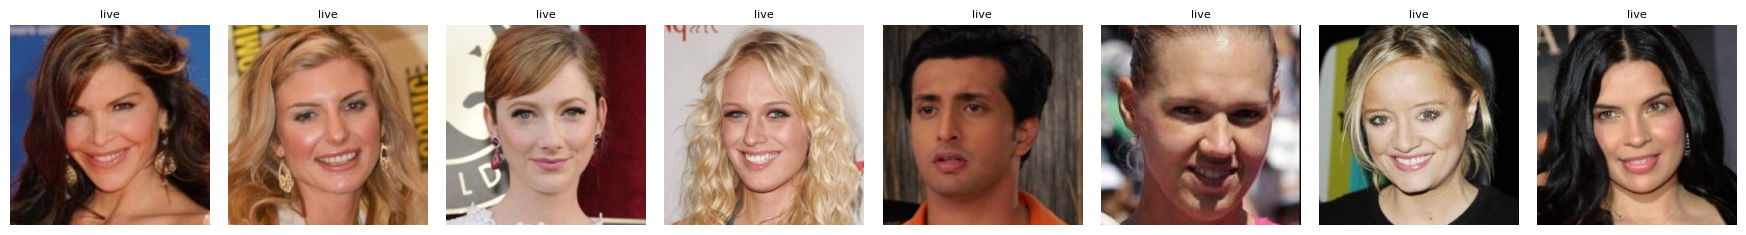

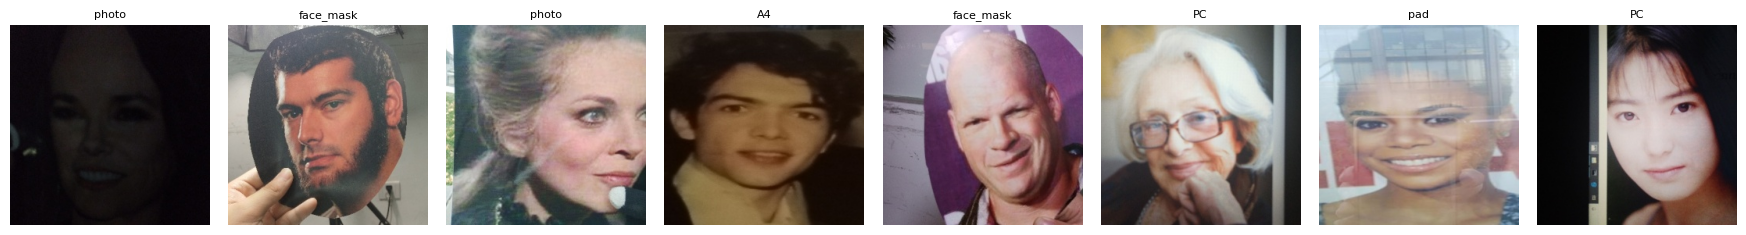

In [ ]:
if CACHE_READY:
    if not CELEBA_CROPS.exists():
        !unzip -q "{CACHE_ZIP}" -d "{CELEBA_CROPS}"
    CELEBA_DF = pd.read_csv(CELEBA_CSV)
    print("loaded cached crops:", CELEBA_CSV)
else:
    t0 = time.time()
    CELEBA_DF = crop_faces(SAMPLE, CELEBA_CROPS, use_bb_fallback=True)
    CELEBA_DF = CELEBA_DF[CELEBA_DF.file.notna()].reset_index(drop=True)
    print(f"crop time: {(time.time() - t0) / 60:.1f} min")
    # save to Drive: one zip (fast to copy) + metadata csv (written last = cache complete)
    shutil.make_archive(str(CACHE_ZIP)[:-4], "zip", CELEBA_CROPS)
    CELEBA_DF.to_csv(CELEBA_CSV, index=False)
    print("crop cache saved:", CACHE_ZIP)

TRAIN_DF = CELEBA_DF[CELEBA_DF.split == "train"].reset_index(drop=True)
VAL_DF = CELEBA_DF[CELEBA_DF.split == "val"].reset_index(drop=True)
assert set(TRAIN_DF.subject.astype(str)).isdisjoint(set(VAL_DF.subject.astype(str)))
print(f"train {len(TRAIN_DF)} | val {len(VAL_DF)} | crop sources {CELEBA_DF.crop_source.value_counts().to_dict()}")

live = TRAIN_DF[TRAIN_DF.label == 0].sample(8, random_state=SEED)
spoof = TRAIN_DF[TRAIN_DF.label == 1].sample(8, random_state=SEED)
show_grid([CELEBA_CROPS / f for f in live.file], ["live"] * 8)
show_grid([CELEBA_CROPS / f for f in spoof.file], spoof.spoof_type.tolist())

## 7. Test set จากรูปที่เราถ่ายเอง (optional)
ใช้แทนการทดสอบข้าม dataset — เป็นกล้องและสภาพแวดล้อมจริงที่จะใช้งาน

วางรูปใน Drive แบบนี้ (ถ้ายังไม่มี จะข้ามส่วนนี้ แล้วค่อยกลับมารันทีหลังได้):
```
MyDrive/roll_call/antispoof/my_test/
├── live/            ← หน้าจริงถ่ายสดจาก webcam / มือถือ
└── spoof/
    ├── print/       ← ถ่ายรูปที่พิมพ์ลงกระดาษ
    ├── phone/       ← ถ่ายรูปหน้าบนจอมือถือ
    └── laptop/      ← ถ่ายรูปหน้าบนจอโน้ตบุ๊ก
```
- crop ด้วยฟังก์ชันเดียวกัน | **ใช้วัดผลอย่างเดียว** ไม่ใช้ train / เลือก threshold / เลือกโมเดล
- แนะนำอย่างน้อย live 50 รูป และ spoof แต่ละแบบ 30 รูป จากหลายคน หลายกล้อง หลายแสง (ขออนุญาตเจ้าของหน้าก่อน)

In [ ]:
MY_CROPS = CROP_DIR / "my_test"
MY_DF = None

if MY_TEST_DIR.exists():
    rows = []
    for p in MY_TEST_DIR.rglob("*"):
        if p.suffix.lower() not in (".jpg", ".jpeg", ".png"):
            continue
        folders = [q.lower() for q in p.relative_to(MY_TEST_DIR).parts]
        if folders[0] in ("live", "real"):
            label, attack = 0, "live"
        elif folders[0] in ("spoof", "fake"):
            label, attack = 1, p.parent.name if len(folders) > 2 else "spoof"
        else:
            continue
        rows.append({"path": str(p), "label": label, "attack": attack})
    MY_DF = pd.DataFrame(rows)
    MY_DF["id"] = [f"m{i:05d}" for i in range(len(MY_DF))]
    print("own photos:", MY_DF.attack.value_counts().to_dict())
    MY_DF = crop_faces(MY_DF, MY_CROPS)
    MY_DF = MY_DF[MY_DF.file.notna()].reset_index(drop=True)
else:
    print(f"no own photos at {MY_TEST_DIR} -> skipped (add later and re-run from this section)")

HAS_MY = MY_DF is not None and (MY_DF.label == 0).any() and (MY_DF.label == 1).any()
if HAS_MY:
    for f in RUNS_DIR.glob("*/eval.json"):   # runs evaluated before the photos existed -> re-evaluate
        if '"my"' not in f.read_text():
            f.unlink()
if HAS_MY:
    show_grid([MY_CROPS / f for f in MY_DF.file[:16]], MY_DF.attack[:16].tolist())

## 8. Augmentation จำลองกล้องหลายแบบ

ต่อภาพ: ด้วยโอกาส `AUG_P` สุ่ม 1–3 ops จากรายการนี้ (ระดับเบาถึงกลาง) แล้วตามด้วย flip / rotate / random crop

| กลุ่ม | ops |
|---|---|
| แสง/สี | brightness/contrast, gamma, hue/saturation, color temperature, CLAHE, shadow |
| กล้องคุณภาพต่ำ | Gaussian noise, ISO noise, JPEG q40–95, downscale 0.5–0.9, motion blur เบา, Gaussian blur เบา |
| เรขาคณิต | horizontal flip, rotation ±10°, random resized crop scale 0.85–1.0 |

**ข้อควรระวัง:** augment แรงเกินจะลบหลักฐานการโกง (moiré จากจอ, texture กระดาษ, สีเพี้ยนของการพิมพ์) จึง **ไม่ใช้ grayscale และไม่ใช้ blur หนัก**

In [ ]:
CAMERA_OP_BUILDERS = [
    # light / color
    lambda: A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1),
    lambda: A.RandomGamma(gamma_limit=(80, 120), p=1),
    lambda: A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=1),
    lambda: A.PlanckianJitter(mode="blackbody", temperature_limit=(4000, 8000), p=1),   # white balance shift
    lambda: A.CLAHE(clip_limit=(1, 2), p=1),
    lambda: A.RandomShadow(p=1),
    # low-quality camera
    lambda: A.GaussNoise(std_range=(0.01, 0.04), p=1),
    lambda: A.ISONoise(color_shift=(0.01, 0.03), intensity=(0.1, 0.3), p=1),
    lambda: A.ImageCompression(quality_range=(40, 95), p=1),
    lambda: A.Downscale(scale_range=(0.5, 0.9), p=1),
    lambda: A.MotionBlur(blur_limit=(3, 5), p=1),
    lambda: A.GaussianBlur(blur_limit=(3, 3), p=1),
]
CAMERA_OPS = []
for build in CAMERA_OP_BUILDERS:   # skip an op (with a warning) if this albumentations version rejects its arguments
    try:
        CAMERA_OPS.append(build())
    except Exception as e:
        print("WARNING: skipped augmentation:", e)
print(f"{len(CAMERA_OPS)} camera ops ready")

def camera_sim(img, p=AUG_P):
    # With probability p, apply 1..AUG_MAX_OPS random camera ops
    if random.random() < p:
        for op in random.sample(CAMERA_OPS, random.randint(1, AUG_MAX_OPS)):
            img = op(image=img)["image"]
    return img

GEOMETRY = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, border_mode=cv2.BORDER_REFLECT_101, p=0.3),
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.85, 1.0), ratio=(0.9, 1.1), p=1),
])
RESIZE = A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_AREA)

def train_transform(img):        # augmentation ON
    return GEOMETRY(image=camera_sim(img))["image"]

def plain_transform(img):        # val / test / "augmentation OFF" ablation
    return RESIZE(image=img)["image"]

def degraded_transform(img):     # "unknown camera" evaluation: always 1-3 camera ops, no geometry
    return RESIZE(image=camera_sim(img, p=1.0))["image"]

12 camera ops ready


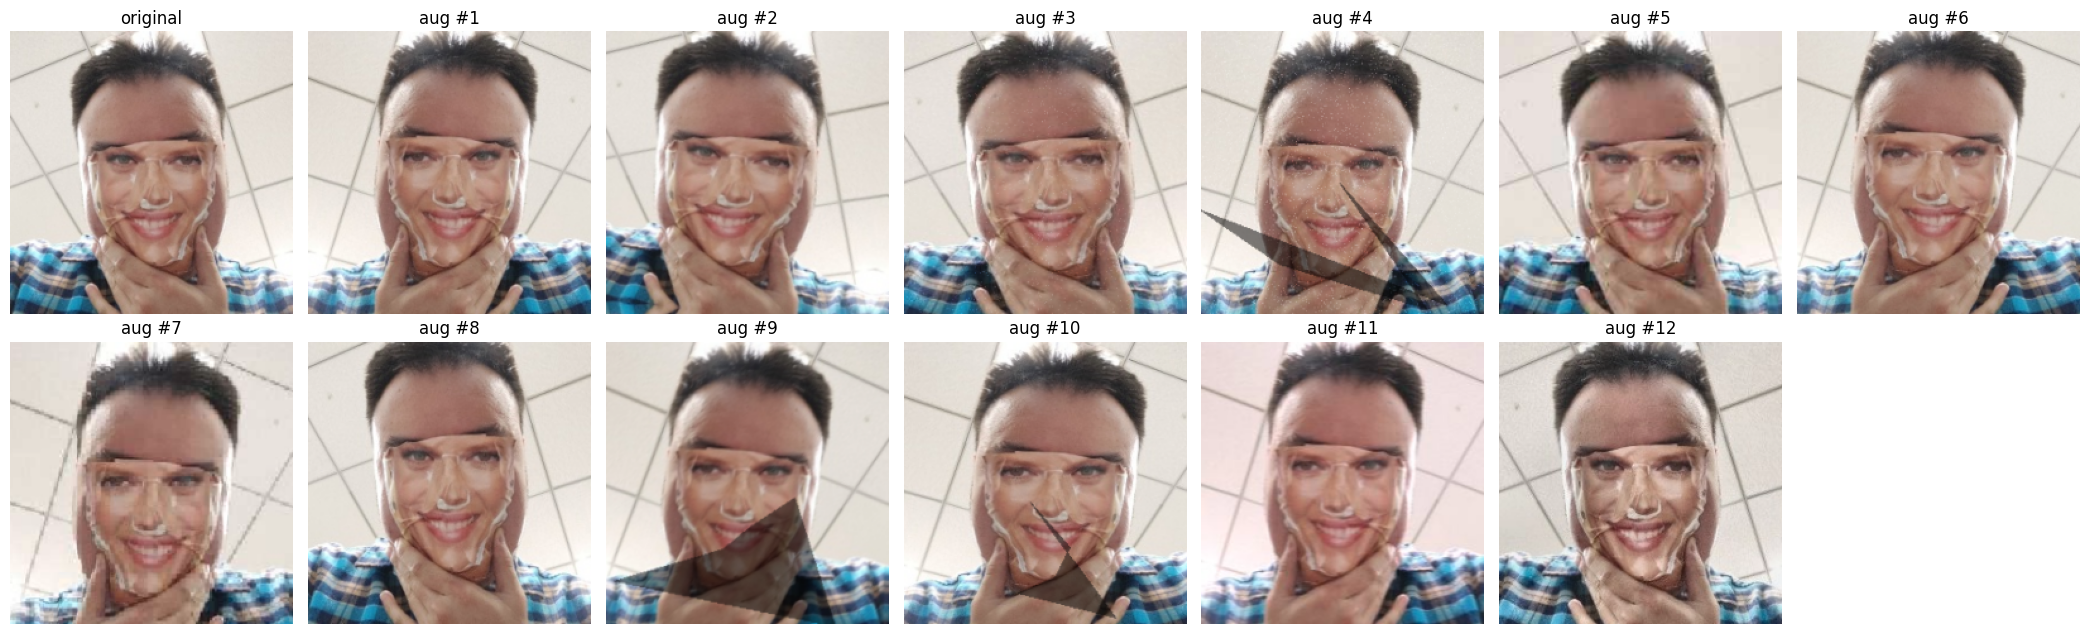

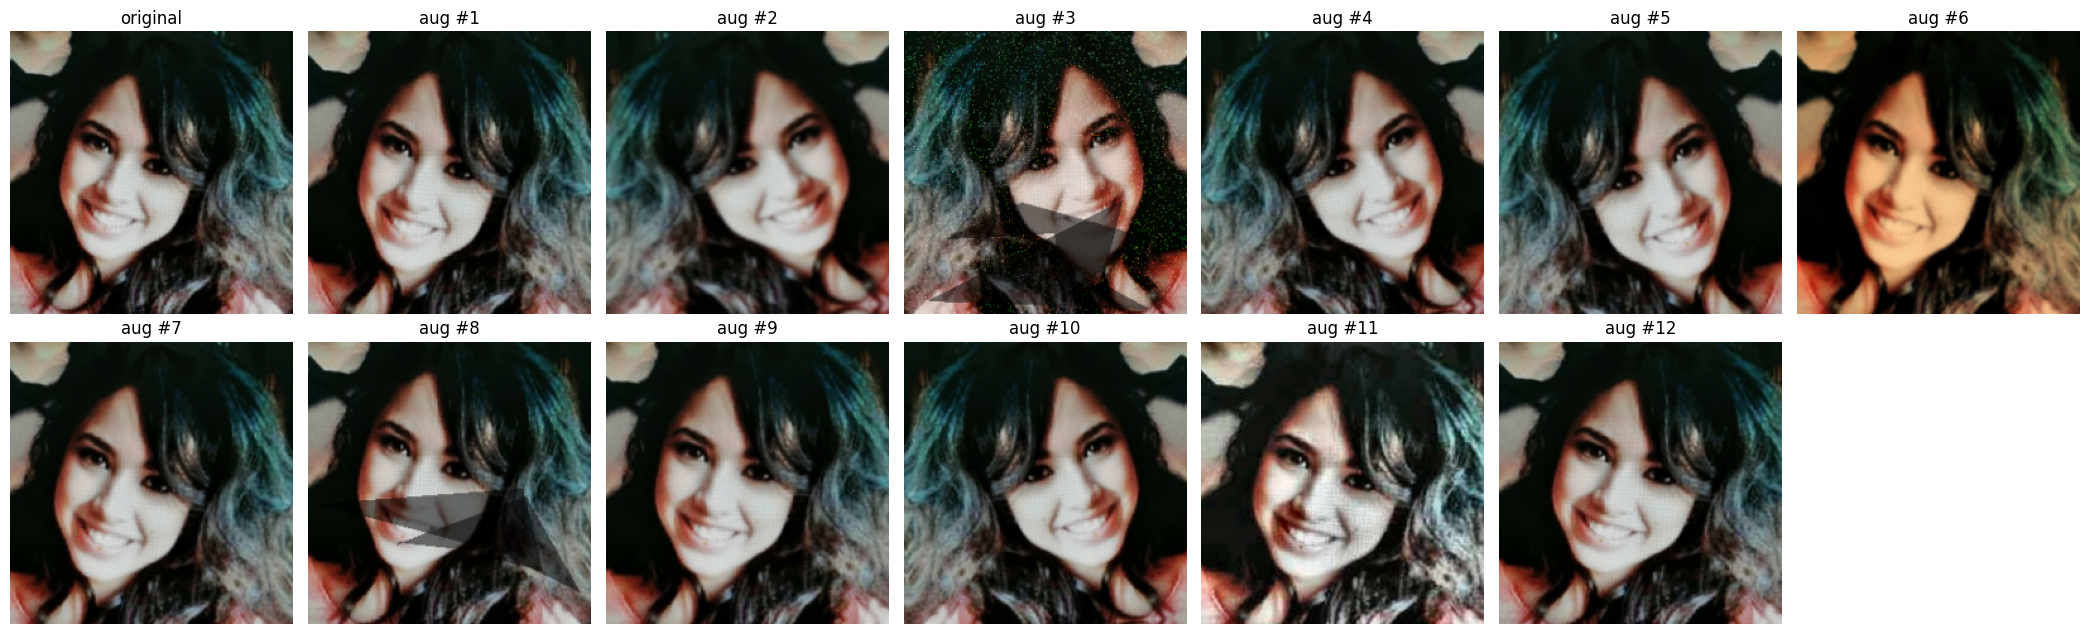

In [ ]:
def preview_augmentation(img_path, n=12):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(2, 7, figsize=(21, 6.5))
    axes = axes.ravel()
    axes[0].imshow(plain_transform(img)); axes[0].set_title("original")
    for i in range(1, n + 1):
        axes[i].imshow(train_transform(img)); axes[i].set_title(f"aug #{i}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout(); plt.show()

random.seed(0)
preview_augmentation(CELEBA_CROPS / TRAIN_DF[TRAIN_DF.label == 1].file.iloc[0])   # spoof: cues should stay visible
preview_augmentation(CELEBA_CROPS / TRAIN_DF[TRAIN_DF.label == 0].file.iloc[0])   # live

In [ ]:
# own photos are optional: if section 7 was skipped, run without them
HAS_MY = globals().get("HAS_MY", False)
MY_DF = globals().get("MY_DF", None)

Y_VAL = VAL_DF.label.values
Y_MY = MY_DF.label.values if HAS_MY else None

## 9. Dataset, metrics, predict

**Metrics มาตรฐาน anti-spoofing** (positive = spoof, score = P(spoof))
- **APCER** = spoof ที่หลุดเป็น live (ช่องโหว่ความปลอดภัย)
- **BPCER** = live ที่ถูกปฏิเสธ (ผู้ใช้รำคาญ)
- **ACER** = (APCER + BPCER) / 2 | **EER** = จุดที่ APCER = BPCER | **AUC** = ไม่ขึ้นกับ threshold

In [ ]:
class CropDataset(Dataset):
    def __init__(self, df, crop_dir, transform, mean, std):
        self.paths = [str(crop_dir / f) for f in df.file]
        self.labels = df.label.values.astype(int)
        self.transform = transform
        self.mean = np.array(mean, np.float32)
        self.std = np.array(std, np.float32)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        img = self.transform(img).astype(np.float32) / 255.0
        img = (img - self.mean) / self.std
        return torch.from_numpy(img.transpose(2, 0, 1).copy()), self.labels[i]

def seed_worker(worker_id):
    # different random augmentations in every DataLoader worker
    seed = torch.initial_seed() % 2**32
    random.seed(seed); np.random.seed(seed)

def make_loader(df, crop_dir, transform, mean, std, train=False):
    return DataLoader(CropDataset(df, crop_dir, transform, mean, std), batch_size=BATCH, shuffle=train,
                      drop_last=train, num_workers=NUM_WORKERS, pin_memory=True, worker_init_fn=seed_worker)

def eer_threshold(y, scores):
    fpr, tpr, thresholds = roc_curve(y, scores)    # fpr = BPCER, 1 - tpr = APCER
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return float(min(thresholds[i], 1.0)), float((fpr[i] + 1 - tpr[i]) / 2)

def compute_metrics(y, scores, threshold):
    y, scores = np.asarray(y), np.asarray(scores)
    pred = (scores >= threshold).astype(int)
    apcer = ((pred == 0) & (y == 1)).sum() / max((y == 1).sum(), 1)
    bpcer = ((pred == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)
    return {"ACER": (apcer + bpcer) / 2, "APCER": apcer, "BPCER": bpcer,
            "AUC": roc_auc_score(y, scores), "EER": eer_threshold(y, scores)[1],
            "ACC": (pred == y).mean(), "threshold": threshold}

@torch.no_grad()
def predict(net, loader, tta=False):
    # returns P(spoof) for every image
    net.eval()
    scores = []
    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            p = net(x).float().softmax(1)[:, 1]
            if tta:
                p = (p + net(x.flip(3)).float().softmax(1)[:, 1]) / 2
        scores.append(p.cpu())
    return torch.cat(scores).numpy()

def norm_stats(backbone):
    cfg = timm.create_model(backbone, pretrained=False).pretrained_cfg
    return list(cfg["mean"]), list(cfg["std"])

def to_multi_gpu(model):
    return nn.DataParallel(model) if N_GPUS > 1 else model

Y_VAL = VAL_DF.label.values
Y_MY = MY_DF.label.values if HAS_MY else None

## 10. Training
- timm backbone (pretrained ImageNet) + หัว 2 class: `0 = live`, `1 = spoof`
- AdamW, cosine schedule + warmup 1 epoch, label smoothing 0.1, AMP (fp16), ใช้ GPU ทุกตัวที่มี (Colab = 1 ตัว)
- **EMA** (`timm.utils.ModelEmaV3`) อัปเดตทุก step และประเมินทั้งโมเดลปกติและ EMA ทุก epoch → ได้ ablation "EMA vs ไม่ EMA" โดยไม่ต้อง train ซ้ำ
- เซฟ `best_model.pt` / `best_ema.pt` ตาม **val ACER** และ `last.pt` ทุก epoch (resume ได้) — run ที่เสร็จแล้วมี `done.json` จะข้าม

In [ ]:
from timm.utils import ModelEmaV3
from timm.optim import create_optimizer_v2
from timm.data import Mixup
from timm.loss import SoftTargetCrossEntropy

def train_run(run):
    run_dir = RUNS_DIR / run["name"]
    run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / "done.json").exists():
        print(f"[{run['name']}] already trained -> skip")
        return
    torch.manual_seed(SEED); random.seed(SEED)

    # ---- data ----
    mean, std = norm_stats(run["backbone"])
    train_loader = make_loader(TRAIN_DF, CELEBA_CROPS, train_transform if run["aug"] else plain_transform,
                               mean, std, train=True)
    val_loader = make_loader(VAL_DF, CELEBA_CROPS, plain_transform, mean, std)

    # ---- model, optimizer, schedule ----
    model = timm.create_model(run["backbone"], pretrained=True, num_classes=2).to(DEVICE)
    net = to_multi_gpu(model)
    optimizer = create_optimizer_v2(model, "adamw", lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * len(train_loader)
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    def lr_factor(step):   # linear warmup, then cosine down to 1% of LR
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler("cuda")
    ema = ModelEmaV3(model, decay=EMA_DECAY, use_warmup=True)

    if run["mixup"]:
        mixup = Mixup(mixup_alpha=0.2, cutmix_alpha=1.0, label_smoothing=LABEL_SMOOTHING, num_classes=2)
        criterion = SoftTargetCrossEntropy()
    else:
        mixup = None
        criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

    # ---- resume ----
    start_epoch, step, history = 0, 0, []
    best = {"model": {"ACER": 1.0, "AUC": 0.0}, "ema": {"ACER": 1.0, "AUC": 0.0}}
    if (run_dir / "last.pt").exists():
        ckpt = torch.load(run_dir / "last.pt", map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model"]); ema.load_state_dict(ckpt["ema"])
        optimizer.load_state_dict(ckpt["optimizer"]); scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        start_epoch, step, history, best = ckpt["epoch"] + 1, ckpt["step"], ckpt["history"], ckpt["best"]
        print(f"[{run['name']}] resumed at epoch {start_epoch + 1}")

    # ---- epochs ----
    for epoch in range(start_epoch, EPOCHS):
        t0 = time.time()
        net.train()
        total_loss = 0.0
        for x, y in tqdm(train_loader, desc=f"{run['name']} epoch {epoch + 1}/{EPOCHS}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            target = y
            if mixup:
                x, target = mixup(x, y)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = criterion(net(x), target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            ema.update(model, step=step)
            total_loss += loss.item()

        # evaluate plain weights and EMA weights on val
        record = {"epoch": epoch + 1, "loss": total_loss / len(train_loader)}
        for variant, weights in [("model", net), ("ema", to_multi_gpu(ema.module))]:
            scores = predict(weights, val_loader)
            m = compute_metrics(Y_VAL, scores, eer_threshold(Y_VAL, scores)[0])
            record[f"{variant}_ACER"], record[f"{variant}_AUC"] = m["ACER"], m["AUC"]
            if (m["ACER"], -m["AUC"]) < (best[variant]["ACER"], -best[variant]["AUC"]):
                best[variant] = {"ACER": m["ACER"], "AUC": m["AUC"], "epoch": epoch + 1}
                src = model if variant == "model" else ema.module
                torch.save(src.state_dict(), run_dir / f"best_{variant}.pt")
        record["minutes"] = (time.time() - t0) / 60
        history.append(record)
        torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                    "step": step, "history": history, "best": best}, run_dir / "last.pt")
        print(f"[{run['name']}] epoch {epoch + 1}/{EPOCHS} | loss {record['loss']:.4f} | "
              f"val ACER model {record['model_ACER']:.4f} / EMA {record['ema_ACER']:.4f} | "
              f"AUC model {record['model_AUC']:.4f} / EMA {record['ema_AUC']:.4f} | {record['minutes']:.1f} min")
        if epoch == start_epoch:
            print(f"   -> about {record['minutes'] * (EPOCHS - epoch - 1):.0f} min left for this run")

    json.dump({"run": run, "history": history, "best": best,
               "train_minutes": sum(h["minutes"] for h in history)},
              open(run_dir / "done.json", "w"), indent=1)
    (run_dir / "last.pt").unlink()   # optimizer state no longer needed; saves disk

## 11. Evaluation
สำหรับแต่ละ run และแต่ละ weights (`model`, `ema`):
1. **val** → threshold ที่จุด EER → ACER / APCER / BPCER / AUC / EER / ACC
2. **val-degraded** → val + camera simulation (1–3 ops ทุกภาพ) × 3 รอบ ใช้ **threshold เดิม** แล้วเฉลี่ย = จำลองกล้องที่ไม่รู้จัก
3. **รูปที่เราถ่ายเอง** (ถ้ามี) ด้วย threshold เดิม
4. **TTA flip** → threshold ใหม่จาก val-TTA แล้วใช้กับรูปของเรา
5. **CPU latency** ต่อภาพ (batch 1)

**คะแนนเลือกโมเดล** = เฉลี่ย ACER ของ val กับ val-degraded (ใช้ val เท่านั้น)

In [ ]:
def load_weights(run, variant):
    model = timm.create_model(run["backbone"], pretrained=False, num_classes=2)
    model.load_state_dict(torch.load(RUNS_DIR / run["name"] / f"best_{variant}.pt", map_location="cpu"))
    return model.to(DEVICE).eval()

CPU_MS = {}
def cpu_latency_ms(backbone, iters=30):
    if backbone not in CPU_MS:
        model = timm.create_model(backbone, pretrained=False, num_classes=2).eval()
        x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
        with torch.inference_mode():
            for _ in range(5):
                model(x)
            t0 = time.perf_counter()
            for _ in range(iters):
                model(x)
        CPU_MS[backbone] = round((time.perf_counter() - t0) / iters * 1000, 1)
    return CPU_MS[backbone]

def evaluate_run(run):
    out_file = RUNS_DIR / run["name"] / "eval.json"
    if out_file.exists():
        return json.load(open(out_file))
    mean, std = norm_stats(run["backbone"])
    val_loader = make_loader(VAL_DF, CELEBA_CROPS, plain_transform, mean, std)
    my_loader = make_loader(MY_DF, MY_CROPS, plain_transform, mean, std) if HAS_MY else None
    result = {"run": run, "cpu_ms": cpu_latency_ms(run["backbone"])}

    for variant in ("model", "ema"):
        net = to_multi_gpu(load_weights(run, variant))
        r = {}
        # 1) clean val + threshold
        s_val = predict(net, val_loader)
        thr = eer_threshold(Y_VAL, s_val)[0]
        r["val"] = compute_metrics(Y_VAL, s_val, thr)
        # 2) degraded val with the SAME threshold
        rounds = []
        for k in range(DEGRADED_ROUNDS):
            random.seed(100 + k)
            rounds.append(compute_metrics(Y_VAL, predict(net, make_loader(VAL_DF, CELEBA_CROPS, degraded_transform, mean, std)), thr))
        r["degraded"] = {key: float(np.mean([m[key] for m in rounds])) for key in rounds[0]}
        r["degraded"]["ACER_std"] = float(np.std([m["ACER"] for m in rounds]))
        # 3) own with the SAME threshold
        scores = {"val": s_val}
        if HAS_MY:
            s_my = predict(net, my_loader)
            r["my"] = compute_metrics(Y_MY, s_my, thr)
            scores["my"] = s_my
        # 4) TTA flip
        if USE_TTA_FLIP:
            s_val_t = predict(net, val_loader, tta=True)
            thr_t = eer_threshold(Y_VAL, s_val_t)[0]
            r["tta_val"] = compute_metrics(Y_VAL, s_val_t, thr_t)
            if HAS_MY:
                r["tta_my"] = compute_metrics(Y_MY, predict(net, my_loader, tta=True), thr_t)
        # attacks that slip through, per spoof type (val)
        spoof_rows = VAL_DF.assign(score=s_val)[VAL_DF.label == 1]
        r["apcer_by_type"] = spoof_rows.groupby("spoof_type").score.apply(lambda s: float((s < thr).mean())).to_dict()
        r["selection_score"] = (r["val"]["ACER"] + r["degraded"]["ACER"]) / 2
        np.savez(RUNS_DIR / run["name"] / f"scores_{variant}.npz", **scores)
        result[variant] = r

    result["best_variant"] = min(("model", "ema"), key=lambda v: result[v]["selection_score"])
    json.dump(result, open(out_file, "w"), indent=1, default=float)
    return json.loads(json.dumps(result, default=float))

def one_line(res):
    v = res[res["best_variant"]]
    own = f"own ACER {v['my']['ACER']:.4f} AUC {v['my']['AUC']:.4f}" if "my" in v else "own n/a"
    return (f"{res['run']['name']:<20} best={res['best_variant']:<5} val ACER {v['val']['ACER']:.4f} "
            f"AUC {v['val']['AUC']:.4f} | degraded ACER {v['degraded']['ACER']:.4f} | {own} | CPU {res['cpu_ms']} ms")

## 12. การทดลอง

### 12.1 เปรียบเทียบ backbone (pipeline และ hyperparameter เดียวกัน)
| backbone | params | ทำไมเลือก |
|---|---|---|
| `mobilenetv3_large_100` | ~5M | เบาและเร็วที่สุดบน CPU |
| `efficientnet_b0` | ~5M | มาตรฐานของงาน anti-spoof |
| `convnext_nano` | ~15M | สถาปัตยกรรมใหม่กว่า มักทน domain shift ได้ดีกว่า ยังรัน real-time บน CPU ได้ |

In [22]:
SHORT = {"mobilenetv3_large_100": "mnv3", "efficientnet_b0": "effb0", "convnext_nano": "convnext"}
RESULTS = {}

for backbone in BACKBONES:
    run = {"name": f"{SHORT.get(backbone, backbone)}_aug", "backbone": backbone, "aug": True, "mixup": False}
    train_run(run)
    RESULTS[run["name"]] = evaluate_run(run)
    print(one_line(RESULTS[run["name"]]))

best_backbone_result = min(RESULTS.values(), key=lambda r: r[r["best_variant"]]["selection_score"])
BEST_BACKBONE = best_backbone_result["run"]["backbone"]
print("\nbest backbone (val selection score):", BEST_BACKBONE)

[mnv3_aug] resumed at epoch 9


mnv3_aug epoch 9/10:   0%|          | 0/265 [00:00<?, ?it/s]

[mnv3_aug] epoch 9/10 | loss 0.2127 | val ACER model 0.0090 / EMA 0.0085 | AUC model 0.9996 / EMA 0.9996 | 0.8 min
   -> about 1 min left for this run


mnv3_aug epoch 10/10:   0%|          | 0/265 [00:00<?, ?it/s]

[mnv3_aug] epoch 10/10 | loss 0.2111 | val ACER model 0.0078 / EMA 0.0093 | AUC model 0.9996 / EMA 0.9996 | 0.8 min
mnv3_aug             best=model val ACER 0.0078 AUC 0.9996 | degraded ACER 0.0160 | own n/a | CPU 17.2 ms


...

convnext_aug epoch 9/10:   0%|          | 0/265 [00:00<?, ?it/s]

[convnext_aug] epoch 9/10 | loss 0.2016 | val ACER model 0.0057 / EMA 0.0060 | AUC model 0.9994 / EMA 0.9997 | 1.4 min


convnext_aug epoch 10/10:   0%|          | 0/265 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b7bb086c040>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b7bb086c040>
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[convnext_aug] epoch 10/10 | loss 0.2012 | val ACER model 0.0058 / EMA 0.0053 | AUC model 0.9994 / EMA 0.9994 | 1.4 min
convnext_aug         best=ema   val ACER 0.0053 AUC 0.9994 | degraded ACER 0.0092 | own n/a | CPU 25.1 ms

best backbone (val selection score): convnext_nano


### 12.2 Ablation บน backbone ที่ดีที่สุด
- **augmentation ปิด vs เปิด** — train ใหม่โดยใช้แค่ resize (ไม่มี camera simulation, flip, rotate)
- **EMA vs ไม่ EMA** — ดูจากแถว `model` กับ `ema` ในตารางด้านล่าง (ทุก run มีทั้งสองแบบ)
- **MixUp/CutMix** (ปิดไว้) — เปิด `RUN_MIXUP_ABLATION = True` เพื่อทดลอง

In [23]:
ablations = []
if RUN_NOAUG_ABLATION:
    ablations.append({"name": f"{SHORT.get(BEST_BACKBONE, BEST_BACKBONE)}_noaug", "backbone": BEST_BACKBONE, "aug": False, "mixup": False})
if RUN_MIXUP_ABLATION:
    ablations.append({"name": f"{SHORT.get(BEST_BACKBONE, BEST_BACKBONE)}_mixup", "backbone": BEST_BACKBONE, "aug": True, "mixup": True})
for run in ablations:
    train_run(run)
    RESULTS[run["name"]] = evaluate_run(run)
    print(one_line(RESULTS[run["name"]]))

# ---- comparison table: one row per (run, weights) ----
rows = []
for name, res in RESULTS.items():
    for variant in ("model", "ema"):
        v = res[variant]
        row = {"run": name, "backbone": res["run"]["backbone"], "aug": res["run"]["aug"],
               "mixup": res["run"]["mixup"], "weights": variant,
               "val_ACER": v["val"]["ACER"], "val_AUC": v["val"]["AUC"], "val_EER": v["val"]["EER"],
               "degraded_ACER": v["degraded"]["ACER"], "selection": v["selection_score"], "cpu_ms": res["cpu_ms"]}
        if "my" in v:
            row.update({"MY_ACER": v["my"]["ACER"], "MY_APCER": v["my"]["APCER"],
                        "MY_BPCER": v["my"]["BPCER"], "MY_AUC": v["my"]["AUC"]})
        if "tta_my" in v:
            row["MY_ACER_tta"] = v["tta_my"]["ACER"]
        if "tta_val" in v:
            row["val_ACER_tta"] = v["tta_val"]["ACER"]
        rows.append(row)
TABLE = pd.DataFrame(rows).sort_values("selection").reset_index(drop=True)
display(TABLE.round(4))

BEST = TABLE.iloc[0]
BEST_RUN = RESULTS[BEST.run]["run"]
BEST_VARIANT = BEST.weights
BEST_EVAL = RESULTS[BEST.run][BEST_VARIANT]
THRESHOLD = BEST_EVAL["val"]["threshold"]
print(f"\nRecommended: {BEST.run} / {BEST_VARIANT} | threshold {THRESHOLD:.4f}")

convnext_noaug epoch 1/10:   0%|          | 0/265 [00:00<?, ?it/s]

/tmp/ipykernel_695/2276019123.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[convnext_noaug] epoch 1/10 | loss 0.2778 | val ACER model 0.0133 / EMA 0.0118 | AUC model 0.9989 / EMA 0.9994 | 1.4 min
   -> about 12 min left for this run


convnext_noaug epoch 2/10:   0%|          | 0/265 [00:00<?, ?it/s]

[convnext_noaug] epoch 2/10 | loss 0.2242 | val ACER model 0.0118 / EMA 0.0070 | AUC model 0.9994 / EMA 0.9996 | 1.3 min


...

[convnext_noaug] epoch 9/10 | loss 0.1986 | val ACER model 0.0102 / EMA 0.0100 | AUC model 0.9983 / EMA 0.9978 | 1.4 min


convnext_noaug epoch 10/10:   0%|          | 0/265 [00:00<?, ?it/s]

[convnext_noaug] epoch 10/10 | loss 0.1985 | val ACER model 0.0102 / EMA 0.0102 | AUC model 0.9983 / EMA 0.9983 | 1.4 min
convnext_noaug       best=ema   val ACER 0.0058 AUC 0.9989 | degraded ACER 0.0477 | own n/a | CPU 25.1 ms


,run,backbone,aug,mixup,weights,val_ACER,val_AUC,val_EER,degraded_ACER,selection,cpu_ms,val_ACER_tta
0,convnext_aug,convnext_nano,True,False,ema,0.0053,0.9994,0.0053,0.0092,0.0072,25.1,0.0052
1,convnext_aug,convnext_nano,True,False,model,0.0057,0.9994,0.0057,0.0102,0.0079,25.1,0.0058
2,mnv3_aug,mobilenetv3_large_100,True,False,model,0.0078,0.9996,0.0078,0.0160,0.0119,17.2,0.0077
3,mnv3_aug,mobilenetv3_large_100,True,False,ema,0.0085,0.9996,0.0085,0.0163,0.0124,17.2,0.0087
4,effb0_aug,efficientnet_b0,True,False,model,0.0098,0.9993,0.0098,0.0170,0.0134,21.1,0.0103
5,effb0_aug,efficientnet_b0,True,False,ema,0.0092,0.9991,0.0092,0.0182,0.0137,21.1,0.0100
6,convnext_noaug,convnext_nano,False,False,ema,0.0058,0.9989,0.0058,0.0477,0.0268,25.1,0.0057
7,convnext_noaug,convnext_nano,False,False,model,0.0070,0.9986,0.0070,0.0507,0.0289,25.1,0.0058



Recommended: convnext_aug / ema | threshold 0.1977


## 13. วิเคราะห์ผล

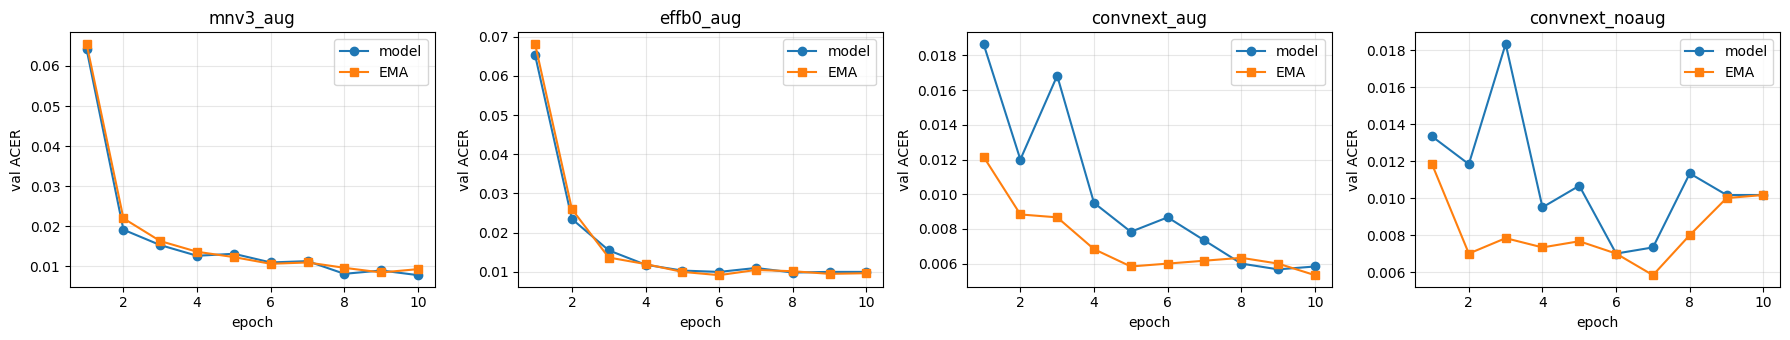

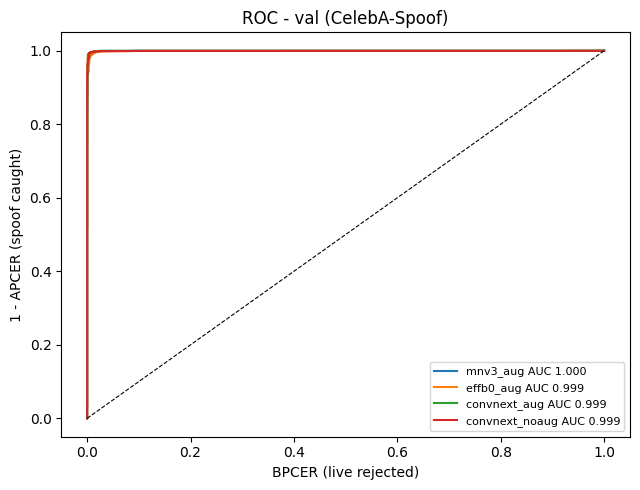

In [24]:
# val ACER per epoch: plain weights vs EMA
fig, axes = plt.subplots(1, len(RESULTS), figsize=(4.5 * len(RESULTS), 3.5), squeeze=False)
for ax, name in zip(axes[0], RESULTS):
    h = pd.DataFrame(json.load(open(RUNS_DIR / name / "done.json"))["history"])
    ax.plot(h.epoch, h.model_ACER, "o-", label="model")
    ax.plot(h.epoch, h.ema_ACER, "s-", label="EMA")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("val ACER"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ROC curves of every run (best weights)
sets = [("val", Y_VAL, "val (CelebA-Spoof)")] + ([("my", Y_MY, "own photos (real cameras)")] if HAS_MY else [])
fig, axes = plt.subplots(1, len(sets), figsize=(6.5 * len(sets), 5), squeeze=False)
for ax, (key, y, title) in zip(axes[0], sets):
    for name, res in RESULTS.items():
        s = np.load(RUNS_DIR / name / f"scores_{res['best_variant']}.npz")[key]
        fpr, tpr, _ = roc_curve(y, s)
        ax.plot(fpr, tpr, label=f"{name} AUC {roc_auc_score(y, s):.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"ROC - {title}"); ax.set_xlabel("BPCER (live rejected)"); ax.set_ylabel("1 - APCER (spoof caught)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

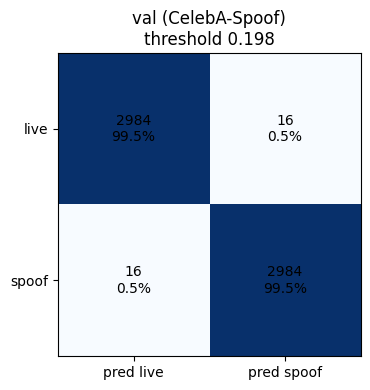

APCER by spoof type (val) - share of attacks accepted as live:


,APCER
pad,0.0237
A4,0.0108
PC,0.0064
photo,0.0037
poster,0.0033
phone,0.0029
3D_mask,0.0000
face_mask,0.0000
region_mask,0.0000
upper_body_mask,0.0000


In [25]:
best_scores = np.load(RUNS_DIR / BEST.run / f"scores_{BEST_VARIANT}.npz")

# confusion matrices at the val threshold
fig, axes = plt.subplots(1, len(sets), figsize=(5 * len(sets), 4), squeeze=False)
for ax, (key, y, title) in zip(axes[0], sets):
    cm = confusion_matrix(y, (best_scores[key] >= THRESHOLD).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{cm[i, j] / max(cm[i].sum(), 1):.1%}", ha="center", va="center")
    ax.set_xticks([0, 1], ["pred live", "pred spoof"]); ax.set_yticks([0, 1], ["live", "spoof"])
    ax.set_title(f"{title}\nthreshold {THRESHOLD:.3f}")
plt.tight_layout(); plt.show()

print("APCER by spoof type (val) - share of attacks accepted as live:")
display(pd.Series(BEST_EVAL["apcer_by_type"]).sort_values(ascending=False).round(4).to_frame("APCER"))

val: 32 mistakes, showing top 16


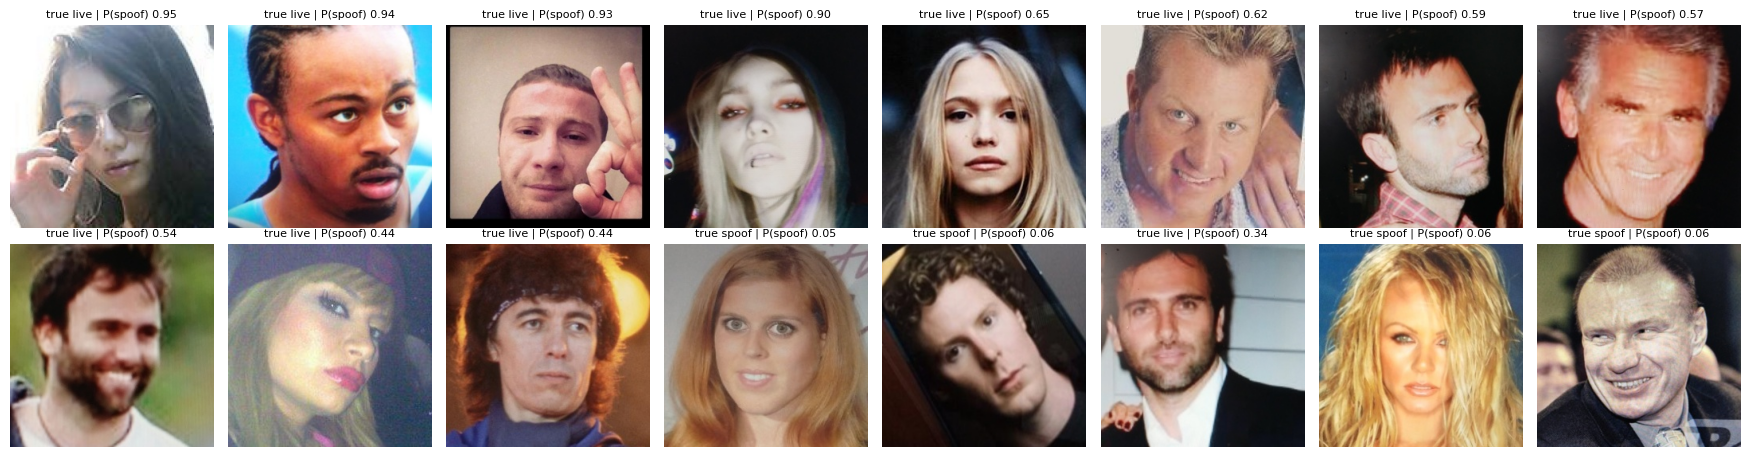

In [26]:
def show_mistakes(df, crop_dir, y, scores, title, k=16):
    pred = (scores >= THRESHOLD).astype(int)
    wrong = np.where(pred != y)[0]
    wrong = wrong[np.argsort(-np.abs(scores[wrong] - THRESHOLD))][:k]   # most confident mistakes first
    print(f"{title}: {(pred != y).sum()} mistakes, showing top {len(wrong)}")
    if len(wrong):
        show_grid([crop_dir / df.file.iloc[i] for i in wrong],
                  [f"true {'live' if y[i] == 0 else 'spoof'} | P(spoof) {scores[i]:.2f}" for i in wrong])

show_mistakes(VAL_DF, CELEBA_CROPS, Y_VAL, best_scores["val"], "val")
if HAS_MY:
    show_mistakes(MY_DF, MY_CROPS, Y_MY, best_scores["my"], "own photos")

### Grad-CAM
ดูว่าโมเดลตัดสินจากส่วนไหนของภาพ — ที่ควรเห็นคือหน้า, ขอบจอ/ขอบกระดาษ, แสงสะท้อน **ไม่ใช่พื้นหลัง**

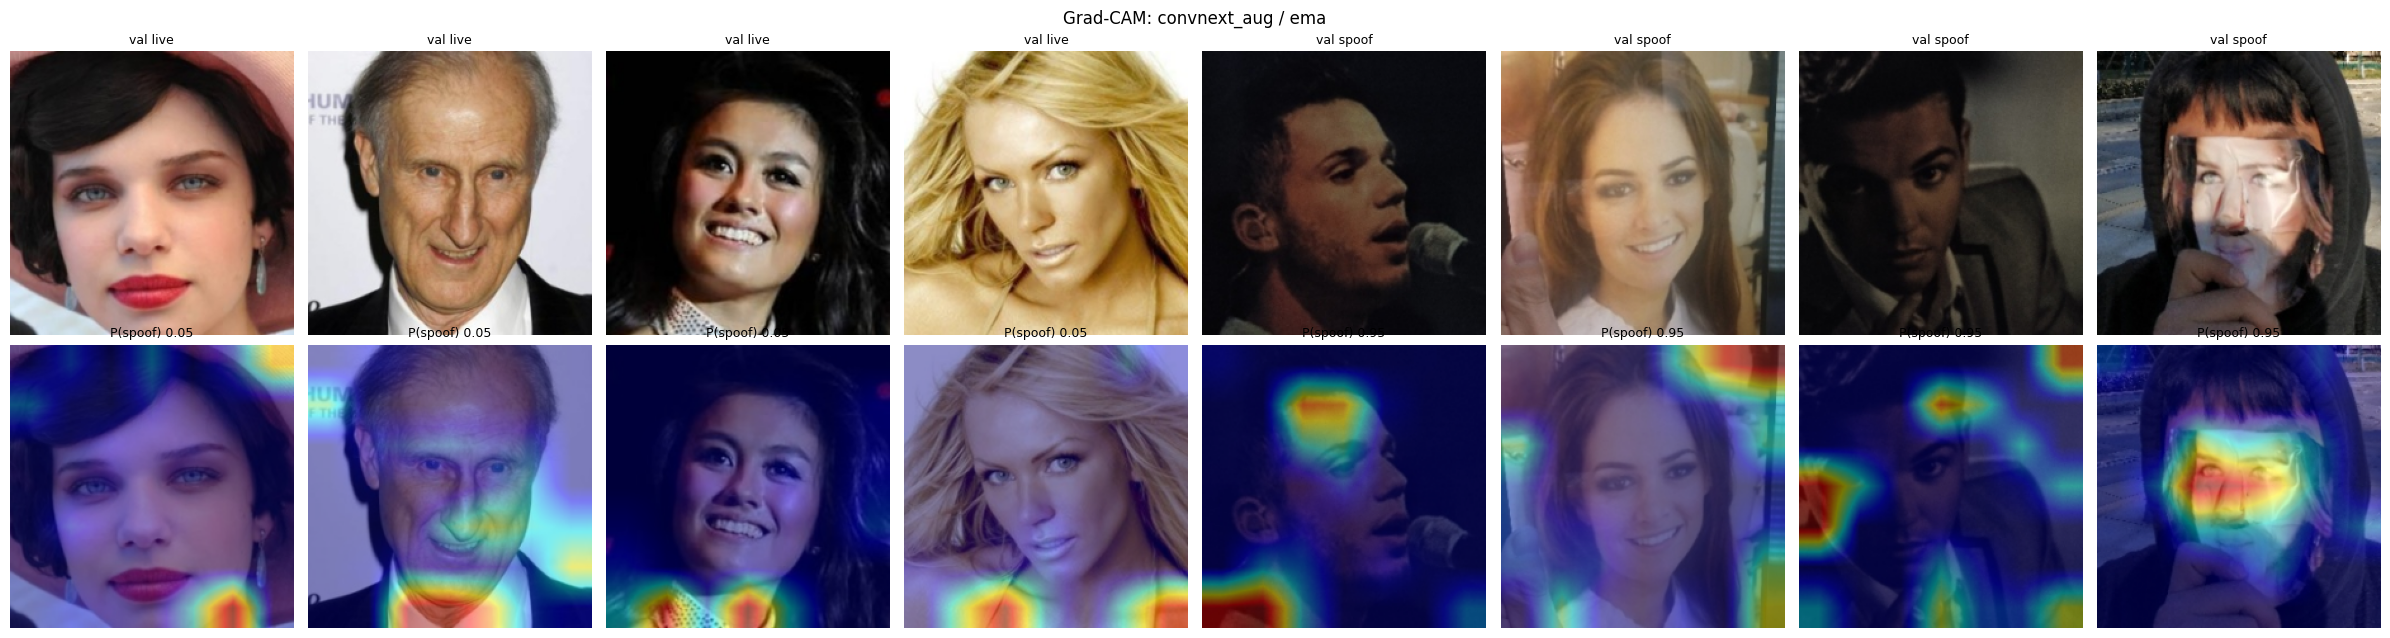

In [27]:
def grad_cam(model, x):
    # Grad-CAM on the last feature map: timm models = forward_features -> forward_head
    feats = model.forward_features(x)
    feats.retain_grad()
    logits = model.forward_head(feats)
    predicted = logits.argmax(1)
    model.zero_grad()
    logits.gather(1, predicted[:, None]).sum().backward()
    weights = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * feats).sum(1, keepdim=True))
    cam = nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear")[:, 0]
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy(), logits.softmax(1)[:, 1].detach().cpu().numpy()

cam_model = load_weights(BEST_RUN, BEST_VARIANT)
mean, std = norm_stats(BEST_RUN["backbone"])
picks = [(VAL_DF, CELEBA_CROPS, "val")]
if HAS_MY:
    picks.append((MY_DF, MY_CROPS, "own"))
examples = []   # (crop path, title)
for df, crop_dir, tag in picks:
    n = 4 if HAS_MY else 8
    for label in (0, 1):
        for f in df[df.label == label].sample(n // 2, random_state=SEED).file:
            examples.append((crop_dir / f, f"{tag} {'live' if label == 0 else 'spoof'}"))

images = [cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB) for p, _ in examples]
x = torch.stack([torch.from_numpy(((plain_transform(im) / 255.0 - mean) / std).transpose(2, 0, 1).astype(np.float32))
                 for im in images]).to(DEVICE)
cams, probs = grad_cam(cam_model, x)

fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6.5))
for i, (img, (_, title)) in enumerate(zip(images, examples)):
    img = plain_transform(img)
    heat = cv2.applyColorMap((cams[i] * 255).astype(np.uint8), cv2.COLORMAP_JET)[:, :, ::-1]
    axes[0, i].imshow(img); axes[0, i].set_title(title, fontsize=9)
    axes[1, i].imshow((0.55 * img + 0.45 * heat).astype(np.uint8)); axes[1, i].set_title(f"P(spoof) {probs[i]:.2f}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle(f"Grad-CAM: {BEST.run} / {BEST_VARIANT}"); plt.tight_layout(); plt.show()

## 14. Export สำหรับระบบจริง
- `.pt` (state_dict + ชื่อ backbone) และ **ONNX** — input `[N, 3, 224, 224]` (RGB, normalized), output = `[P(live), P(spoof)]` (ใส่ softmax ไว้ในโมเดลแล้ว)
- เทียบ ONNX กับ PyTorch บน 64 ภาพ val (ค่าต่างสูงสุดต้อง < 1e-3 และตัดสินผลตรงกัน 100%)
- `antispoof_config.json` — ระบบจริงอ่านไฟล์นี้เพื่อ crop / preprocess / threshold ให้เหมือนตอน train ทุกอย่าง

In [28]:
import onnxruntime as ort

class WithSoftmax(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        return self.model(x).softmax(1)

export_name = f"antispoof_{BEST.run}_{BEST_VARIANT}"
PT_PATH = EXPORT_DIR / f"{export_name}.pt"
ONNX_PATH = EXPORT_DIR / f"{export_name}.onnx"
CONFIG_PATH = EXPORT_DIR / "antispoof_config.json"

model = load_weights(BEST_RUN, BEST_VARIANT).cpu().float()
torch.save({"state_dict": model.state_dict(), "backbone": BEST_RUN["backbone"], "num_classes": 2}, PT_PATH)

wrapped = WithSoftmax(model).eval()
export_args = dict(input_names=["input"], output_names=["probs"], opset_version=17,
                   dynamic_axes={"input": {0: "batch"}, "probs": {0: "batch"}})
try:
    torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), str(ONNX_PATH), dynamo=False, **export_args)
except TypeError:   # older torch has no `dynamo` argument
    torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), str(ONNX_PATH), **export_args)

# check: ONNX == PyTorch
mean, std = norm_stats(BEST_RUN["backbone"])
check_ds = CropDataset(VAL_DF.sample(64, random_state=SEED), CELEBA_CROPS, plain_transform, mean, std)
xb = torch.stack([check_ds[i][0] for i in range(len(check_ds))])
with torch.inference_mode():
    p_torch = wrapped(xb).numpy()
session = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
p_onnx = session.run(None, {"input": xb.numpy()})[0]
MAX_DIFF = float(np.abs(p_torch - p_onnx).max())
SAME_DECISION = float(((p_torch[:, 1] >= THRESHOLD) == (p_onnx[:, 1] >= THRESHOLD)).mean())
t0 = time.perf_counter()
for _ in range(30):
    session.run(None, {"input": xb[:1].numpy()})
ONNX_MS = round((time.perf_counter() - t0) / 30 * 1000, 1)
print(f"ONNX vs PyTorch: max diff {MAX_DIFF:.1e} | same decision {SAME_DECISION:.0%} | ONNX CPU {ONNX_MS} ms/img")

config = {
    "backbone": BEST_RUN["backbone"], "weights": BEST_VARIANT, "run": BEST.run,
    "onnx_file": ONNX_PATH.name, "pt_file": PT_PATH.name,
    "img_size": IMG_SIZE, "color": "RGB", "layout": "NCHW",
    "normalize": {"scale": "pixel / 255", "mean": mean, "std": std},
    "class_order": ["live", "spoof"], "onnx_output": "probabilities (softmax included)",
    "threshold": THRESHOLD, "decision": "spoof if P(spoof) >= threshold",
    "threshold_source": "EER point on CelebA-Spoof val (subject-disjoint)",
    "face_detector": {"weights": YOLO_WEIGHTS.name, "imgsz": YOLO_IMGSZ, "conf": YOLO_CONF,
                      "pick": "face with the highest confidence"},
    "crop": {"scale": CROP_SCALE,
             "box": "square, side = max(w, h) * scale, same center as the face box",
             "outside_image": "shift the box inside the image; if side > min(W, H) use side = min(W, H)",
             "resize": f"crop -> {IMG_SIZE}x{IMG_SIZE}, cv2.INTER_AREA"},
    "metrics": {"val": BEST_EVAL["val"], "val_degraded": BEST_EVAL["degraded"], "my": BEST_EVAL.get("my")},
}
json.dump(config, open(CONFIG_PATH, "w"), indent=1, default=float)
print("saved:", PT_PATH, ONNX_PATH, CONFIG_PATH, sep="\n  ")

/tmp/ipykernel_695/3041524023.py:22: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), str(ONNX_PATH), dynamo=False, **export_args)


ONNX vs PyTorch: max diff 6.6e-07 | same decision 100% | ONNX CPU 22.3 ms/img
saved:
  /content/drive/MyDrive/roll_call/antispoof/export/antispoof_convnext_aug_ema.pt
  /content/drive/MyDrive/roll_call/antispoof/export/antispoof_convnext_aug_ema.onnx
  /content/drive/MyDrive/roll_call/antispoof/export/antispoof_config.json


## 15. สรุปผล (copy ข้อความด้านล่างกลับไปให้ดู)
ไฟล์ทั้งหมดอยู่ใน Google Drive `MyDrive/roll_call/antispoof/export/`

In [29]:
def fmt(d):
    return ", ".join(f"{k}={v:.4f}" for k, v in d.items() if isinstance(v, (int, float)))

lines = [
    "===== NOTEBOOK 2 SUMMARY (Kaggle): anti-spoofing live vs spoof =====",
    f"Env        : torch {torch.__version__}, timm {timm.__version__}, {N_GPUS}x {torch.cuda.get_device_name(0)}, CPU cores {NUM_WORKERS}",
    f"Crop       : {YOLO_WEIGHTS.name} @ {YOLO_IMGSZ}, conf {YOLO_CONF}, scale {CROP_SCALE}, img {IMG_SIZE}",
    f"CelebA     : train {len(TRAIN_DF)} / val {len(VAL_DF)} (subject-disjoint), crop sources {CELEBA_DF.crop_source.value_counts().to_dict()}",
    f"own photos : " + (f"{len(MY_DF)} imgs (live {(Y_MY == 0).sum()}, spoof {(Y_MY == 1).sum()})" if HAS_MY else "not used"),
    f"Train      : epochs {EPOCHS}, batch {BATCH}, lr {LR}, wd {WEIGHT_DECAY}, smoothing {LABEL_SMOOTHING}, EMA {EMA_DECAY}",
    "Selection  : lowest mean(val ACER, degraded ACER); threshold = val EER point; own never used for selection",
    "",
    TABLE.round(4).to_string(index=False),
    "",
    f"RECOMMENDED: {BEST.run} / {BEST_VARIANT} ({BEST_RUN['backbone']}), threshold {THRESHOLD:.4f}",
    f"  val      : {fmt(BEST_EVAL['val'])}",
    f"  degraded : {fmt(BEST_EVAL['degraded'])}",
    f"  own      : {fmt(BEST_EVAL['my']) if 'my' in BEST_EVAL else 'n/a'}",
    f"  TTA flip : val ACER {BEST_EVAL['tta_val']['ACER']:.4f} (no TTA {BEST_EVAL['val']['ACER']:.4f})"
    + (f", own ACER {BEST_EVAL['tta_my']['ACER']:.4f} (no TTA {BEST_EVAL['my']['ACER']:.4f})" if "tta_my" in BEST_EVAL else "")
    if "tta_val" in BEST_EVAL else "  TTA flip : off",
    "  APCER by type: " + ", ".join(f"{k}={v:.3f}" for k, v in sorted(BEST_EVAL["apcer_by_type"].items(), key=lambda kv: -kv[1])),
    f"  ONNX     : max diff {MAX_DIFF:.1e}, same decision {SAME_DECISION:.0%}, CPU {ONNX_MS} ms/img",
    f"Files      : {PT_PATH}",
    f"             {ONNX_PATH}",
    f"             {CONFIG_PATH}",
    "=====================================================================",
]
SUMMARY = "\n".join(lines)
(DRIVE_DIR / "summary.txt").write_text(SUMMARY)
print(SUMMARY)

===== NOTEBOOK 2 SUMMARY (Kaggle): anti-spoofing live vs spoof =====
Env        : torch 2.11.0+cu130, timm 1.0.30, 1x NVIDIA L4, CPU cores 12
Crop       : yolo26s_widerface_960_best.pt @ 640, conf 0.25, scale 1.5, img 224
CelebA     : train 34000 / val 6000 (subject-disjoint), crop sources {'yolo': 39921, 'bb': 79}
own photos : not used
Train      : epochs 10, batch 128, lr 0.0003, wd 0.05, smoothing 0.1, EMA 0.998
Selection  : lowest mean(val ACER, degraded ACER); threshold = val EER point; own never used for selection

           run              backbone   aug  mixup weights  val_ACER  val_AUC  val_EER  degraded_ACER  selection  cpu_ms  val_ACER_tta
  convnext_aug         convnext_nano  True  False     ema    0.0053   0.9994   0.0053         0.0092     0.0072    25.1        0.0052
  convnext_aug         convnext_nano  True  False   model    0.0057   0.9994   0.0057         0.0102     0.0079    25.1        0.0058
      mnv3_aug mobilenetv3_large_100  True  False   model    0.0078   0